# 05 · Budget-constrained offer allocation

The champion uplift model says *which offers pay*. A real Nectar Prices programme also has limits: a fixed discount budget for the cycle, and only a few personalised offers shown to each member. This notebook turns model scores into an **offer plan** under those limits (`src/nectar/optimise/`).

For each test-set (member, offer) pair:
- **value** = champion's predicted incremental gross profit if the offer is sent;
- **cost** = predicted retailer-funded discount cost if sent, from a separate cost model trained on the offer group's observed discount spend.

The integer programme maximises total value subject to the discount budget, a per-member cap and optional per-offer caps, and never sends a pair with value ≤ 0. A value-per-cost greedy rule is the fast fallback. Scale: 602 test members, one 4-week cycle.

In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from nectar import viz
from nectar.viz import BLUE, ORANGE, GREY, TEXT_2
from nectar.config import WAREHOUSE_PATH
from nectar.optimise.allocate import Constraints, solve_greedy, solve_ilp
from nectar.optimise.run import build_candidates

viz.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
cand = build_candidates()
champion = cand.attrs["champion"]
true_profit = lambda sel: float(cand.gt_profit_uplift.to_numpy()[sel].sum())
print(f"Champion: {champion} | candidates: {len(cand):,} pairs, {cand.member_id.nunique()} members")

Champion: X-learner | candidates: 10,836 pairs, 602 members


## 1. Is the cost model good enough to budget with?

In [2]:
r = np.corrcoef(cand.cost, cand.true_cost)[0, 1]
pos = cand.value > 0
pd.DataFrame({
    "predicted total": [cand.cost.sum(), cand.cost[pos].sum()],
    "true total": [cand.true_cost.sum(), cand.true_cost[pos].sum()],
}, index=["offer every pair", "offer pairs with value > 0"]).assign(
    error=lambda d: d["predicted total"] / d["true total"] - 1)

,predicted total,true total,error
offer every pair,"2,090.65","2,132.94",-0.02
offer pairs with value > 0,280.14,267.36,0.05


In [3]:
print(f"Correlation of predicted and true expected cost per pair: {r:.2f}")

Correlation of predicted and true expected cost per pair: 0.89


Totals are within a few percent of the truth, so the budget the optimiser plans with is close to the budget it will really spend.

## 2. Profit against budget, and what the per-member cap costs

In [4]:
budgets = [10, 25, 50, 75, 100, 150, 200, 250, 300]
caps = {"1 offer": 1, "3 offers": 3, "5 offers": 5, "no cap": 99}
rows = []
for label, k in caps.items():
    for b in budgets:
        a = solve_ilp(cand, Constraints(budget=b, max_per_member=k))
        rows.append({"cap": label, "budget": b, "offers": int(a.selected.sum()), "spend": a.spend,
                     "predicted_profit": a.objective, "true_profit": true_profit(a.selected),
                     "shadow_price": a.shadow_price})
grid = pd.DataFrame(rows)

def fill_budget(order, budget, k):
    """Baseline: walk a ranking and send offers until the budget or member cap is hit."""
    sel = np.zeros(len(cand), bool); spent = 0.0; per = {}
    mem, cost = cand.member_id.to_numpy(), cand.cost.to_numpy()
    for i in order:
        if spent + cost[i] > budget or per.get(mem[i], 0) >= k:
            continue
        sel[i] = True; spent += cost[i]; per[mem[i]] = per.get(mem[i], 0) + 1
    return sel

rng = np.random.default_rng(0)
random_order = rng.permutation(len(cand))
resp_order = np.argsort(-cand["score__Response model"].to_numpy())
base = pd.DataFrame([{"budget": b,
                      "Random": true_profit(fill_budget(random_order, b, 99)),
                      "Response model": true_profit(fill_budget(resp_order, b, 99))} for b in budgets])
grid.pivot(index="budget", columns="cap", values="true_profit")[list(caps)].join(base.set_index("budget"))

,1 offer,3 offers,5 offers,no cap,Random,Response model
budget,,,,,,
10,7.06,7.27,8.78,8.86,-6.86,-10.99
25,13.36,18.27,21.17,23.67,-17.69,-20.20
50,16.98,31.18,38.96,48.01,-29.91,-37.88
75,12.23,37.21,47.33,69.67,-42.81,-55.06
100,12.23,36.79,52.62,87.05,-58.19,-75.93
150,12.23,29.17,52.96,112.58,-88.45,-109.96
200,12.23,29.17,46.34,119.60,-119.95,-149.58
250,12.23,29.17,46.33,113.76,-145.50,-187.87
300,12.41,29.17,46.33,107.11,-168.69,-222.88


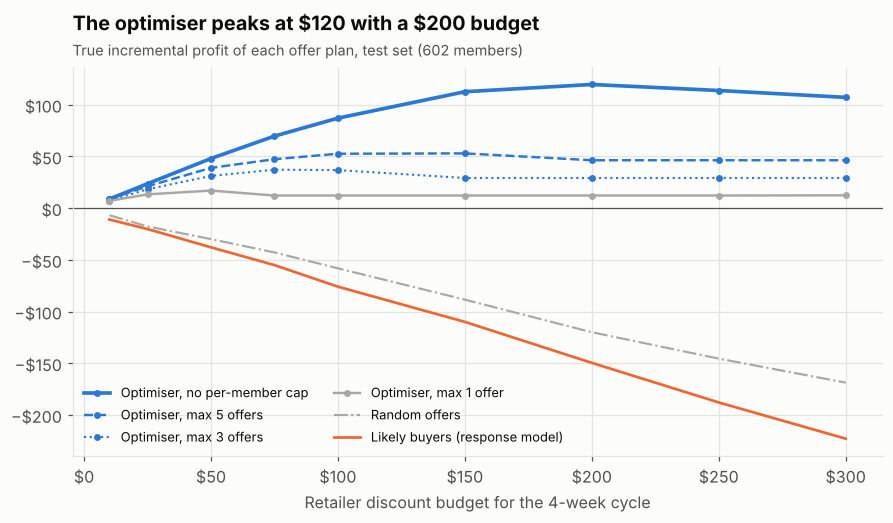

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
styles = {"no cap": (BLUE, 2.4, "-"), "5 offers": (BLUE, 1.6, "--"), "3 offers": (BLUE, 1.4, ":"),
          "1 offer": (GREY, 1.6, "-")}
for label, (col, lw, ls) in styles.items():
    g = grid[grid.cap == label]
    ax.plot(g.budget, g.true_profit, color=col, lw=lw, ls=ls, marker="o", ms=3.5,
            label=f"Optimiser, max {label}" if label != "no cap" else "Optimiser, no per-member cap")
ax.plot(base.budget, base["Random"], color=GREY, lw=1.4, ls="-.", label="Random offers")
ax.plot(base.budget, base["Response model"], color=ORANGE, lw=1.8, label="Likely buyers (response model)")
ax.axhline(0, color=TEXT_2, lw=0.8)
ax.xaxis.set_major_formatter(viz.money(0)); ax.yaxis.set_major_formatter(viz.money(0))
ax.set_xlabel("Retailer discount budget for the 4-week cycle")
ax.grid(axis="x")
best = grid.loc[grid[grid.cap == "no cap"].true_profit.idxmax()]
ax.set_title(f"The optimiser peaks at {viz.money(0)(best.true_profit)} with a {viz.money(0)(best.budget)} budget")
viz.subtitle(ax, "True incremental profit of each offer plan, test set (602 members)")
ax.legend(loc="lower left", fontsize=8.5, ncol=2)
viz.save(fig, "19_budget_curves"); fig

In [6]:
nocap = grid[grid.cap == "no cap"].set_index("budget")
b100 = grid[grid.budget == 100].set_index("cap").loc[list(caps), ["offers", "true_profit"]]
b100["vs no cap"] = b100.true_profit / b100.loc["no cap", "true_profit"] - 1
b100

,offers,true_profit,vs no cap
cap,,,
1 offer,503,12.23,-0.86
3 offers,1082,36.79,-0.58
5 offers,1353,52.62,-0.40
no cap,1615,87.05,0.00


**Reading the curves**

- **More budget is not always better.** Profit peaks and then falls: beyond the peak, the extra offers are pairs the model *thinks* pay but which really don't. A budget is a useful brake on model error.
- **The per-member cap is expensive.** Persuadable members tend to respond across many categories, so capping offers per member blocks the most valuable pairs. At a $100 budget the table above shows the cost of each cap. That is a number to bring to the product team before fixing how many offers the app shows.
- **Likely-buyer targeting loses more money the more budget it gets.**

## 3. Exact optimisation vs a greedy rule

In [7]:
cmp_rows = []
for b in [25, 50, 100, 150]:
    c3 = Constraints(budget=b, max_per_member=3)
    a, g = solve_ilp(cand, c3), solve_greedy(cand, c3)
    cmp_rows.append({"budget": b, "ILP predicted": a.objective, "greedy predicted": g.objective,
                     "ILP true": true_profit(a.selected), "greedy true": true_profit(g.selected)})
cmp = pd.DataFrame(cmp_rows).set_index("budget")
cmp

,ILP predicted,greedy predicted,ILP true,greedy true
budget,,,,
25,47.76,44.70,18.27,14.26
50,67.46,58.93,31.18,11.37
100,85.54,65.63,36.79,-5.66
150,89.82,65.63,29.17,-5.66


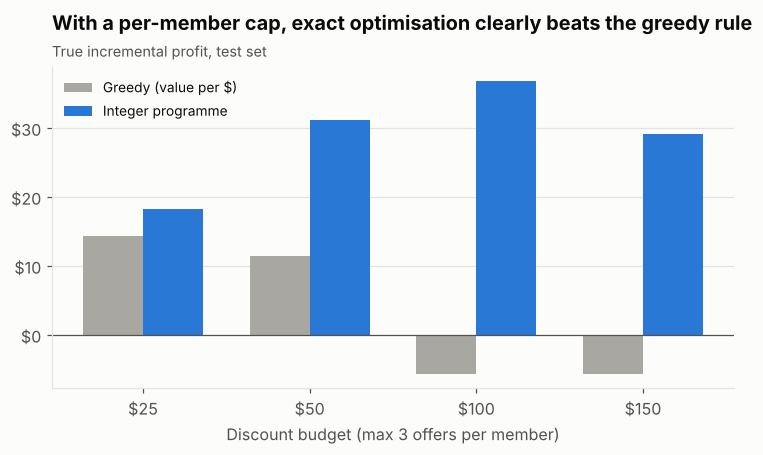

In [8]:
x = np.arange(len(cmp)); w = 0.36
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x - w / 2, cmp["greedy true"], width=w, color=GREY, label="Greedy (value per $)")
ax.bar(x + w / 2, cmp["ILP true"], width=w, color=BLUE, label="Integer programme")
ax.axhline(0, color=TEXT_2, lw=0.8)
ax.set_xticks(x, [viz.money(0)(b) for b in cmp.index])
ax.yaxis.set_major_formatter(viz.money(0))
ax.set_xlabel("Discount budget (max 3 offers per member)")
ax.set_title("With a per-member cap, exact optimisation clearly beats the greedy rule")
viz.subtitle(ax, "True incremental profit, test set")
ax.legend(loc="upper left", fontsize=9)
viz.save(fig, "20_ilp_vs_greedy"); fig

Greedy ranking by value per $ is near-optimal when the budget is the only limit. With per-member caps it wastes each member's few slots on cheap, low-value offers. The integer programme solves this test set in under a second, so speed is no reason to settle for greedy here.

## 4. How much is one more $1 of budget worth?

The shadow price of the budget constraint (from the linear-programme relaxation) is the predicted extra profit from one more $1 of discount budget.

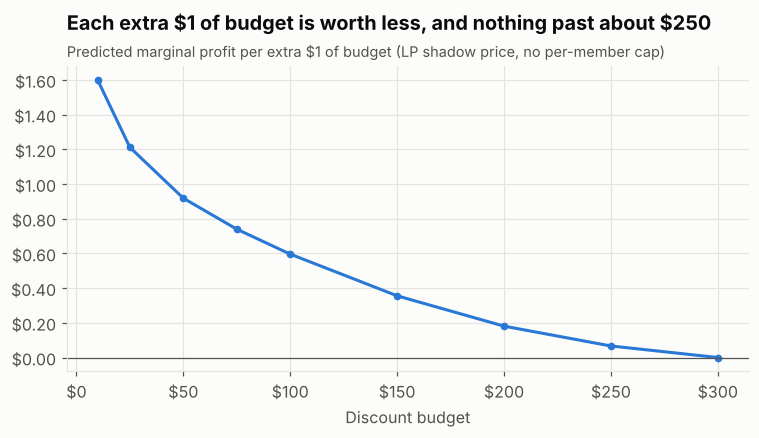

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(nocap.index, nocap.shadow_price, color=BLUE, marker="o", ms=4)
ax.axhline(0, color=TEXT_2, lw=0.8)
ax.xaxis.set_major_formatter(viz.money(0)); ax.yaxis.set_major_formatter(viz.money(2))
ax.set_xlabel("Discount budget"); ax.grid(axis="x")
ax.set_title("Each extra $1 of budget is worth less, and nothing past about $250")
viz.subtitle(ax, "Predicted marginal profit per extra $1 of budget (LP shadow price, no per-member cap)")
viz.save(fig, "21_shadow_price"); fig

`value` is already net of the discount cost, so any positive shadow price means more budget still adds *predicted* profit: $0.92 per extra $1 at a $50 budget, $0.36 at $150, under $0.10 by $250. The model is optimistic, though (next section), so the real marginal value is lower. Once the shadow price is small next to that bias, extra budget is more likely to lose money than make it. Here that happens at about $150–200.

## 5. The optimiser's curse

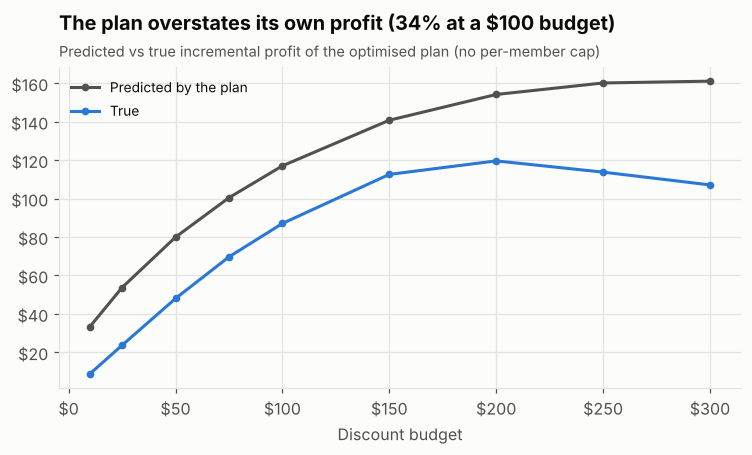

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(nocap.index, nocap.predicted_profit, color=TEXT_2, marker="o", ms=4, label="Predicted by the plan")
ax.plot(nocap.index, nocap.true_profit, color=BLUE, marker="o", ms=4, label="True")
ax.xaxis.set_major_formatter(viz.money(0)); ax.yaxis.set_major_formatter(viz.money(0))
ax.set_xlabel("Discount budget"); ax.grid(axis="x")
gap = (nocap.predicted_profit / nocap.true_profit - 1).loc[100]
ax.set_title(f"The plan overstates its own profit ({gap:.0%} at a $100 budget)")
viz.subtitle(ax, "Predicted vs true incremental profit of the optimised plan (no per-member cap)")
ax.legend(loc="upper left", fontsize=9)
viz.save(fig, "22_optimisers_curse"); fig

Choosing the pairs with the highest *predicted* value also chooses the pairs whose value was most *over*-predicted. The plan's own forecast is therefore biased upwards. In practice, report the forecast from a randomised holdout (members eligible for the plan but held back), not the optimiser's objective.

## 6. The recommended plan: $150 budget, no per-member cap

$150 is chosen without using the ground truth: it is where the predicted marginal return has fallen to about a third of a dollar, a safety margin against the plan's roughly 25–35% optimism.

Who gets offers, and which offers?

In [11]:
plan_c = Constraints(budget=150, max_per_member=99)
plan = solve_ilp(cand, plan_c)
sel = cand[plan.selected]
con = duckdb.connect(str(WAREHOUSE_PATH), read_only=True)
rfm = con.execute("SELECT member_id, segment FROM marts.mart_member_rfm").df()
con.close()
seg = (cand.drop_duplicates("member_id").merge(rfm, on="member_id").segment.value_counts(normalize=True)
       .rename("share_of_members").to_frame())
seg["share_of_offers"] = sel.merge(rfm, on="member_id").segment.value_counts(normalize=True)
seg = seg.fillna(0).sort_values("share_of_offers", ascending=False)
print(f"Plan: {plan.selected.sum():,} offers to {sel.member_id.nunique()} of {cand.member_id.nunique()} members | "
      f"expected cost {viz.money(0)(plan.spend)} | true profit {viz.money(0)(true_profit(plan.selected))}")
seg

Plan: 2,066 offers to 420 of 602 members | expected cost $150 | true profit $113


,share_of_members,share_of_offers
segment,,
Lost,0.19,0.34
Hibernating,0.13,0.19
Potential loyalists,0.09,0.12
Needs attention,0.09,0.11
Champions,0.26,0.08
At risk,0.09,0.06
About to sleep,0.01,0.05
Loyal,0.13,0.04
"Recent, low value",0.00,0.01


Offers go mainly to members with **lapsed or occasional** buying (Lost, Hibernating, Potential loyalists). Champions are a quarter of members but receive only a small share of offers: they already buy, so discounts would mostly subsidise purchases that happen anyway.

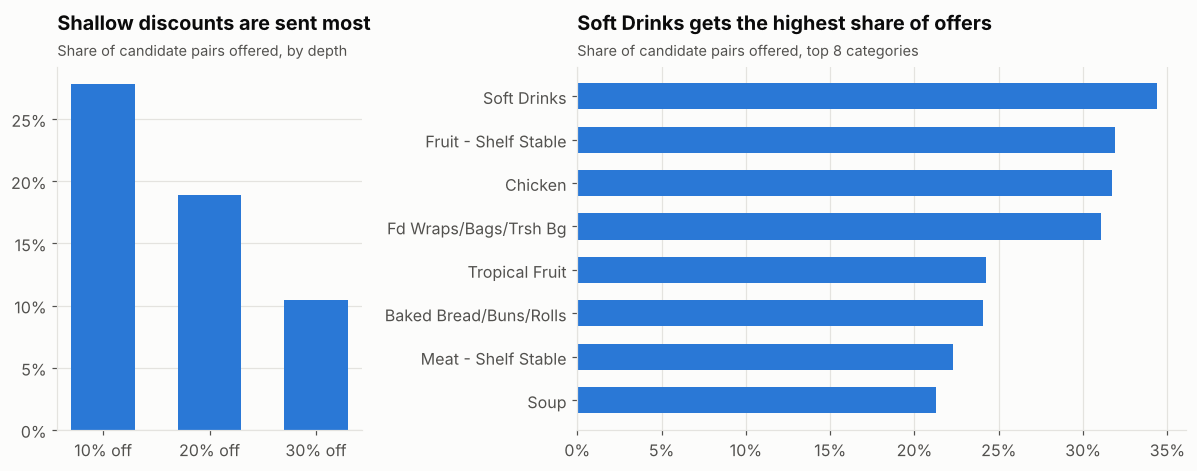

In [12]:
depth = sel.groupby("discount_pct").size() / cand.groupby("discount_pct").size()
cat = (sel.groupby("commodity").size() / cand.groupby("commodity").size()).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1, 2]})
ax = axes[0]
ax.bar([f"{d:.0%} off" for d in depth.index], depth.values, color=BLUE, width=0.6)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_title("Shallow discounts are sent most")
viz.subtitle(ax, "Share of candidate pairs offered, by depth")
ax = axes[1]
top = cat.head(8).iloc[::-1]
ax.barh(top.index.str.title(), top.values, color=BLUE, height=0.6)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_title(f"{top.index[-1].title()} gets the highest share of offers")
viz.subtitle(ax, "Share of candidate pairs offered, top 8 categories")
fig.tight_layout()
viz.save(fig, "23_plan_profile"); fig

## Summary

| Question | Answer (test set, 602 members, one 4-week cycle) |
|---|---|
| Can the cost side be predicted? | Yes: total expected discount cost is within a few percent of the truth |
| Best budget | Profit peaks around a $150–200 budget; beyond that, extra offers lose money |
| Price of a per-member cap | Large: capping at 3 offers keeps only a fraction of the uncapped profit at $100 |
| ILP vs greedy | With caps, the exact solver clearly beats greedy and runs in under a second |
| Forecast honesty | The plan's predicted profit is biased upwards: measure with a randomised holdout |

**Next (week 8):** a FastAPI service that scores a member's candidate offers and returns their plan, packaged in Docker.